# Ramsey Experiment

In [1]:
from nqct.utils.QuantumSession import QuantumSession

# api_key = input('Enter API Key') #<---PASTE_API_KEY_HERE instead of the input(...)
# qs = QuantumSession(api_key=api_key, storage_path='temp/')
qs = QuantumSession(api_key="nqct_wN194hn5LE7W9qVBEt8BjMQXGUqIufBpqHvG5tumqHo")
qs.list_backends();
#Copy over the desired backend from the given list
qs.select_backend('quantware_soprano_d2')

,Name,Backend ID,Qubits
0,Qiskit Aer Simulator,aer_simulator,5
1,QuantWare Soprano D2,quantware_soprano_d2,7


We continue on from the Rabi experiment to showcase a Ramsey experiment. The Ramsey experiment is designed to map out z-rotations on a qubit. To actually see z-rotations, the idea is to:

- First rotate the qubit onto the xy-plane (so that z-rotations actually change the state) via a $X(\pi/2)$
- Then we let the qubit evolve about the z-axis by sweeping the wait times. The resulting rotations will just be the ensemble average of a stochastic noise (decoherence). To make the dynamics more obvious, we offset the frequency off resonance (not enough to make the Hamiltonian tilt away from the x-axis when driving the qubits - i.e. the x-rotations are still fine).
- To measure the resulting rotation, we rotate the qubit via a $X(\pi/2)$ operation to map the qubit back onto the z-axis.

The resulting oscillations should be equal to the offset frequency with decay time-constant $T_2^*$ signifying the coherence time of the qubit. In the following experiments, we need to offset the frequency. We do so by first finding the qubit names:

In [2]:
qs.get_qubit_names()

['Q0', 'Q1', 'Q2', 'Q3', 'Q4']

and querying their properties. In this case, we wish to get the `DriveGE` frequency:

In [3]:
dict_qubit_params = qs.get_qubit_params('Q0')
drive_freq = dict_qubit_params['DriveGE']
drive_freq

5141379243.105709

## Simple Ramsey using the pre-tuned gates

Here we use the pre-tuned gates to perform the rotations. The following script uses pure OpenQASM3 where we use the `cal` block to set the drive frequency of qubit $0 off-resonant by 250kHz above:

In [4]:
my_script = f"""
OPENQASM 3;
include 'stdgates_transmon_fixed_coupler.inc';

cal
{{
    set_frequency(drive0, {drive_freq+250e3});
}}
"""

my_script += r"""
bit[60] c;
qubit q;

for int m in [0:59]
{
    reset q;
    rx(pi/2) q;
    delay[m*400ns] q;
    rx(pi/2) q;
    c[m] = measure q;
}
"""
qs.set_qasm(my_script)
qs.set_qreg_physical_mapping({('q',0):0})

Setup readout parameters and execute

In [5]:
qs.set_acquisition_type('DISCRIMINATION')
qs.set_averaging_type('SingleShotCounts')
qs.set_num_shots(1024)
qs.set_shot_repeat(1)
#
leRes = qs.run()

The resulting array slices over the 21 bit register measurements, each with 1024 shots (i.e. 0 or 1). So take the average on each measurement over all its shots and plot the Rabi oscillations:

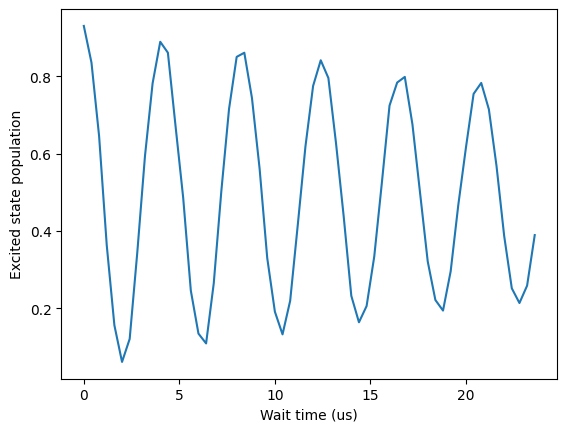

In [6]:
import numpy as np
import matplotlib.pyplot as plt

cur_arrs = leRes.get_data('c')
pops_e = np.mean(cur_arrs, axis=1)

fig, ax = plt.subplots(1); ax.set_xlabel('Wait time (us)'); ax.set_ylabel('Excited state population')
ax.plot(400e-9*np.arange(60) * 1e6, pops_e);

## Simple Ramsey using the pulse-control

Now we perform the same experiment, but using the low-level pulse control via OpenPulse constructs. We won't redo the Rabi to get the calibrated $X(\pi/2)$ amplitudes. Instead we will use the current calibration given by NQCT:

In [7]:
X_pi2_ampl, X_pi2_time = dict_qubit_params['DriveGEAmplitudeXon2'], dict_qubit_params['DriveGETime']

Now we pass these onto a custom Ramsey pulse sequence where we vary the delay inside the OpenPulse constructs within the `defcal` command:

In [8]:
my_script = f"""
OPENQASM 3;
include 'stdgates_transmon_fixed_coupler.inc';

cal
{{
    set_frequency(drive0, {drive_freq+250e3});

	const float X_pi2_ampl = {X_pi2_ampl};
	const duration X_pi2_time = {X_pi2_time*1e9}ns;
}}


bit[60] c;
bit[2] calib;
qubit q;
"""

my_script += r"""

defcal ramsey(duration wait_time) $0
{
	play(drive($0), gaussian(X_pi2_time, X_pi2_ampl));
	//The delay command in OpenPulse is per line instead of per qubit like in OpenQASM.
	//Also using a predefined drive0=drive($0) as delay commands require literals.
	delay[wait_time] drive0;
	play(drive($0), gaussian(X_pi2_time, X_pi2_ampl));
}

//Take calibration traces
//Ground
reset q;
calib[0] = measure q;
//Excited (could use OpenPulse constructs, but let's just use the pre-calibrated x-gate)
reset q;
x q;
calib[1] = measure q;

//Perform the Ramsey experiment
for int m in [0:59]
{
	reset q;

	//This automatically calls our defcal as q is mapped to qubit $0.
	ramsey(m*400ns) q;

	c[m] = measure q;
}
"""
qs.set_qasm(my_script)
qs.set_qreg_physical_mapping({('q',0):0})

Once again, like with the Rabi example, we take calibration points for G and E as we will once again not presume that we have calibrated the readout. Thus, let's just take in the raw IQ values integrated over 1024 shots:

In [9]:
qs.set_acquisition_type('INTEGRATION')
qs.set_averaging_type('AverageRepetitions')
qs.set_num_shots(1024)
qs.set_shot_repeat(1)

leRes = qs.run()

Similar to the Rabi example, we will use the normalisation utility to get the corrected populations:

Frequency: 240.4kHz
T2*: 35.5us


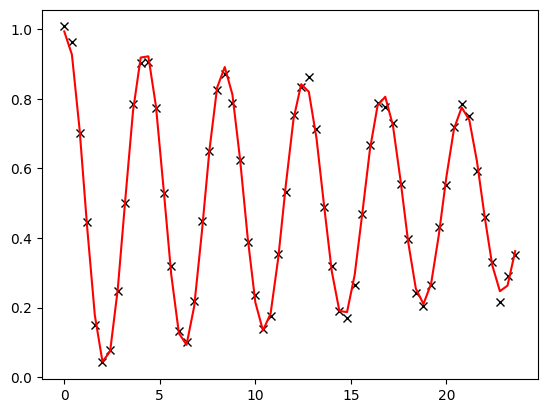

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sqdtoolz.Utilities.DataFitting import DFitSinusoid
from sqdtoolz.Utilities.DataIQNormalise import DataIQNormalise

rabi_arrs = np.array(leRes.get_data('c'))
calib_arrs = np.array(leRes.get_data('calib'))

#The class accepts multiple sampled points for G and E, since we only have 1, we nest the array...
dNorm = DataIQNormalise([calib_arrs[0]], [calib_arrs[1]])
normalised_data = dNorm.normalise_data(rabi_arrs)

dfit = DFitSinusoid()
dpkt = dfit.get_fitted_plot(np.arange(60)*400e-9 * 1e6, normalised_data)
print(f"Frequency: {dpkt['frequency']*1e3:.4g}kHz\nT2*: {1/dpkt['decay_rate']:.3g}us")

The decay rate here gives the $T_2^*$ while the frequency matches the offset frequency - i.e. signifying that the calibrated resonant frequency is accurate.